## Setup

In [23]:
%run ./2_preprocessing.ipynb

import numpy as np
from sklearn.base import clone
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV

from sklearn.model_selection import GridSearchCV, StratifiedKFold

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

import pandas as pd
import matplotlib.pyplot as plt
import joblib

Numerical: ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']


,IQR_lower,IQR_upper,Flagged_count,Flagged_min,Flagged_max
Age,15.50,27.50,2,28.0,28.00
Sleep_Hours,3.75,9.75,9,3.6,10.00
Study_Hours_Per_Week,4.00,36.00,7,2.4,38.30
GPA,1.60,3.52,5,1.5,3.66
Social_Media_Hours,3.05,9.05,10,2.1,10.00
Screen_Time_Hours,3.95,13.15,7,3.3,14.00
Attendance_Rate,65.35,104.95,10,54.4,65.30


,Student_ID,Study_Hours_Per_Week
866,STU0867,2.4
1042,STU1043,2.7
453,STU0454,3.2
519,STU0520,3.6
340,STU0341,3.9
937,STU0938,37.5
716,STU0717,38.3


,num__Age,num__Year_of_Study,num__Sleep_Hours,num__Study_Hours_Per_Week,num__GPA,num__Social_Media_Hours,num__Screen_Time_Hours,num__Financial_Stress,num__Family_Support,num__Attendance_Rate,binary__Part_Time_Job,binary__Previous_Mental_Health_History,ordinal__Physical_Activity,ordinal__Diet_Quality,nominal__Gender_Female,nominal__Gender_Male,nominal__Gender_Non-binary
726,-0.063706,-0.471636,-1.404182,-0.238603,0.074214,0.148597,1.098992,0.713748,0.643008,-1.244652,0.0,0.0,0.191167,0.080487,1.0,0.0,0.0
1384,0.875744,-1.232340,-1.676036,-1.330997,-0.976093,0.327697,0.194658,-0.842691,0.368687,-0.465696,0.0,0.0,1.581473,0.080487,1.0,0.0,0.0
1579,-1.003157,-0.471636,0.408177,-0.516037,-1.034443,-0.299153,-0.830254,-0.305988,0.752736,0.772288,0.0,0.0,0.191167,0.080487,1.0,0.0,0.0
1098,0.875744,-1.232340,1.404975,-0.082547,0.891120,0.775447,1.098992,0.821088,-0.948052,-0.215317,0.0,0.0,0.191167,0.080487,1.0,0.0,0.0
582,0.406019,0.289067,0.408177,0.663055,-0.275888,-0.388703,-0.347943,0.660077,0.697872,-1.453301,1.0,1.0,1.581473,0.080487,1.0,0.0,0.0


Training shape: (1600, 17)
Test shape: (400, 17)
Missing values: 0


,Count,Percent
Mental_Health_Risk,,
High,544,34.0
Medium,528,33.0
Low,528,33.0


## Models

In [24]:
candidates = {
    "Logistic Regression": Pipeline(
        [
            ("preprocessor", clone(preprocessor)),
            ("model", LogisticRegression(max_iter=2000)),
        ]
    ),
    "SVM": CalibratedClassifierCV(
        estimator=Pipeline(
            [("preprocessor", clone(preprocessor)), ("model", SVC(kernel="rbf"))]
        ),
        cv=5,
        ensemble=False,
    ),
}

## Hyperparameters

In [25]:
param_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10]},
    "SVM": {
        "estimator__model__C": [0.1, 1, 10],
        "estimator__model__gamma": ["scale", 0.01, 0.1],
    },
}

## GridSearchCV

In [26]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

searches = {}

for name, estimator in candidates.items():
    print(f"\nTuning {name}")

    search = GridSearchCV(
        estimator=estimator,
        param_grid=param_grids[name],
        scoring="f1_weighted",
        cv=cv,
        refit=True,
        return_train_score=True,
        n_jobs=1,
        verbose=1,
        error_score="raise",
    )

    search.fit(X_train, y_train)

    searches[name] = search

    print("Best parameters:", search.best_params_)
    print("Best CV weighted F1:", round(search.best_score_, 3))


Tuning Logistic Regression
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'model__C': 10}
Best CV weighted F1: 0.752

Tuning SVM
Fitting 5 folds for each of 9 candidates, totalling 45 fits
Best parameters: {'estimator__model__C': 10, 'estimator__model__gamma': 0.01}
Best CV weighted F1: 0.737


## Compare tuned with baseline

In [27]:
baseline_params = {
    "Logistic Regression": {"model__C": 1},
    "SVM": {"estimator__model__C": 1, "estimator__model__gamma": "scale"},
}

rows = []

for name, search in searches.items():
    results = search.cv_results_
    best_index = search.best_index_

    baseline_index = results["params"].index(baseline_params[name])

    baseline_f1 = results["mean_test_score"][baseline_index]
    tuned_f1 = search.best_score_

    rows.append(
        {
            "Model": name,
            "Baseline CV F1": baseline_f1,
            "Tuned CV F1": tuned_f1,
            "Change": tuned_f1 - baseline_f1,
            "Train F1": results["mean_train_score"][best_index],
            "CV F1 std": results["std_test_score"][best_index],
            "Best parameters": search.best_params_,
        }
    )

tuning_comparison = (
    pd.DataFrame(rows).set_index("Model").sort_values("Tuned CV F1", ascending=False)
)

display(tuning_comparison.round(3))

,Baseline CV F1,Tuned CV F1,Change,Train F1,CV F1 std,Best parameters
Model,,,,,,
Logistic Regression,0.751,0.752,0.001,0.766,0.021,{'model__C': 10}
SVM,0.717,0.737,0.020,0.795,0.013,"{'estimator__model__C': 10, 'estimator__model_..."


## Final Model

In [28]:
final_name = tuning_comparison["Tuned CV F1"].idxmax()

final_search = searches[final_name]
final_model = final_search.best_estimator_

print("Selected model:", final_name)
print("Parameters:", final_search.best_params_)

Selected model: Logistic Regression
Parameters: {'model__C': 10}


## Evaluate selected model on test

In [29]:
y_pred = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)

test_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),

    "Weighted precision": precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    ),

    "Weighted recall": recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    ),

    "Weighted F1": f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    ),

    "Weighted ROC-AUC": roc_auc_score(
        y_test,
        y_proba,
        labels=final_model.classes_,
        multi_class="ovr",
        average="weighted"
    )
}

display(
    pd.Series(test_metrics, name="Test score").round(3)
)

Accuracy              0.755
Weighted precision    0.756
Weighted recall       0.755
Weighted F1           0.755
Weighted ROC-AUC      0.914
Name: Test score, dtype: float64

## Prediction Errors

              precision    recall  f1-score   support

         Low      0.822     0.803     0.812       132
      Medium      0.632     0.636     0.634       132
        High      0.812     0.824     0.818       136

    accuracy                          0.755       400
   macro avg      0.755     0.754     0.755       400
weighted avg      0.756     0.755     0.755       400



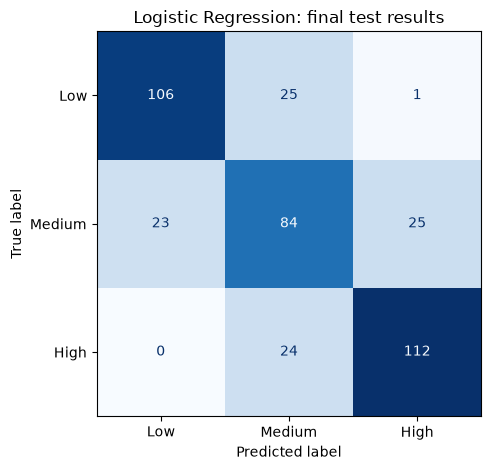

High-label false negatives: 24
High-label false positives: 26


,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Actual,Predicted,Correct
720,22,Female,4,5.9,21.7,2.23,6.1,9.0,Moderate,3.1,9.4,86.5,Yes,Poor,No,Low,Medium,False
1624,25,Male,1,6.9,19.7,2.35,6.4,8.8,Low,6.8,7.2,75.3,Yes,Poor,No,Medium,High,False
1854,23,Male,1,7.8,4.9,2.15,6.3,9.9,Low,6.1,5.9,78.7,Yes,Good,No,High,Medium,False
1130,22,Female,3,8.4,18.5,2.47,5.8,8.1,High,3.0,3.4,75.7,No,Poor,No,Medium,Low,False
1071,22,Male,1,6.1,17.9,2.22,5.5,8.7,High,2.4,7.7,87.9,Yes,Average,No,Medium,Low,False
1522,21,Male,5,6.5,22.5,2.38,NaN,7.9,High,6.5,8.8,84.7,No,Average,No,Medium,Low,False
911,21,Female,5,6.3,25.6,2.60,6.9,8.3,Moderate,4.6,6.2,84.5,No,Good,No,Medium,Low,False
1887,22,Male,3,6.2,15.1,2.64,8.0,10.5,Low,4.3,4.8,82.1,No,Average,No,Medium,High,False
1084,22,Female,1,8.3,14.3,2.37,7.2,7.6,Moderate,5.4,NaN,71.2,No,Average,No,Medium,Low,False
274,19,Female,2,6.9,19.8,2.49,3.8,6.7,High,2.8,4.5,79.5,No,Average,Yes,Medium,Low,False


,Students,Accuracy
Gender,,
Female,192,0.792
Male,186,0.710
Non-binary,22,0.818


In [30]:
risk_order = ["Low", "Medium", "High"]

print(
    classification_report(y_test, y_pred, labels=risk_order, digits=3, zero_division=0)
)

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=risk_order, cmap="Blues", colorbar=False
)

plt.title(f"{final_name}: final test results")
plt.tight_layout()
plt.show()


high_false_negatives = ((y_test == "High") & (y_pred != "High")).sum()

high_false_positives = ((y_test != "High") & (y_pred == "High")).sum()

print("High-label false negatives:", high_false_negatives)
print("High-label false positives:", high_false_positives)

test_review = X_test.copy()

test_review["Actual"] = y_test
test_review["Predicted"] = y_pred
test_review["Correct"] = test_review["Actual"] == test_review["Predicted"]

errors = test_review.loc[~test_review["Correct"]]

display(errors.head(10))


group_results = (
    test_review.groupby("Gender")["Correct"]
    .agg(["count", "mean"])
    .rename(columns={"count": "Students", "mean": "Accuracy"})
)

display(group_results.round(3))

## Saving the Model

In [31]:
model_dir = root / "models"
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "mental_health_pipeline.joblib"

joblib.dump(final_model, model_path)

print("Saved to:", model_path)

loaded_model = joblib.load(model_path)

np.testing.assert_array_equal(loaded_model.predict(X_test), y_pred)

print("Saved model reloaded successfully.")

Saved to: /home/saikyouboi/Documents/AI-BRIEFS/mental-health-risk-prediction/models/mental_health_pipeline.joblib
Saved model reloaded successfully.


In [32]:
import json
import sklearn

metadata = {
    "model": final_name,
    "best_parameters": final_search.best_params_,
    "cv_weighted_f1": float(final_search.best_score_),
    "test_metrics": {key: float(value) for key, value in test_metrics.items()},
    "feature_columns": X_train.columns.tolist(),
    "classes": final_model.classes_.tolist(),
    "sklearn_version": sklearn.__version__,
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "joblib_version": joblib.__version__,
    "split_random_state": 42,
}

(model_dir / "model_metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)

882